# Clean-Hour: when is electricity cleanest?
AI + Climate track. [GitHub repo](https://github.com/Harshal623/clean-hour)

**The idea.** Power plants burn more coal and gas at some hours than
others, so the same EV charge or dishwasher run can emit very different
CO2 depending on when it starts. We forecast the carbon intensity of a
regional power grid (grams of CO2 per kWh) and recommend the cleanest
window for a flexible job.

**Our user.** A Northern Virginia family at 6 PM, deciding when to
charge the car, on the PJM grid. A Loudoun data-center lead with batch
work to schedule is the same forecast.

**The test.** We train on 2023 to 2025 and test on every day of 2026.
The model never sees 2026 while training, and at 6 PM it only uses what
was known then. Nothing is shuffled. We compare against simple rules and
against perfect hindsight.

**What is in this notebook.** The pipeline that produces our headline
numbers, in the order it runs: four source files, then the training run,
then the app. Our extra experiments live in `src/experiments/` with
write-ups in `docs/experiments/`: a PyTorch Transformer on a Colab GPU,
a decision-trained second stage, a 6 PM plug-in baseline, an estimated
marginal-emissions check and a year-robustness test.

**Honest limits.** The signal is the average emissions of a whole
regional grid, not the marginal plant and not one town. Savings are
measured against starting at midnight (the 6 PM comparison is in
`results/experiments/plug_in_baseline.csv`). This is a backtest on past
days, not a live forecast; the Live tab uses the official forecasters.

**How to use it.** Click Runtime, then Run all. Training takes about a
minute on a laptop and a few minutes on Colab's free CPU. To skip it, set
`RETRAIN = False` in section 3 and the saved results are used instead.

## 1. Setup
Get the repo (it holds the small data files) and install what the app needs. Gradio is pinned because the app was built and tested against 4.44.

In [1]:
import os
import subprocess
import sys

in_colab = "google.colab" in sys.modules

if not os.path.exists("data/compact"):
    if os.path.basename(os.getcwd()) == "notebooks":
        os.chdir("..")
    else:
        repo = "https://github.com/Harshal623/clean-hour.git"
        clone = subprocess.run(["git", "clone", "-q", repo], capture_output=True, text=True)
        if clone.returncode or not os.path.isdir("clean-hour"):
            raise SystemExit("Could not clone the repo:\n" + clone.stderr[-1500:])
        os.chdir("clean-hour")

install = subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q",
     "numpy", "pandas", "scikit-learn", "matplotlib",
     "gradio==4.44.1", "huggingface_hub<1.0"],
    capture_output=True, text=True,
)
if install.returncode:
    raise SystemExit("pip install failed:\n" + install.stderr[-2000:])

os.makedirs("src", exist_ok=True)
os.makedirs("app", exist_ok=True)
print("Setup complete:", "Google Colab" if in_colab else "local run")

Setup complete: local run


## 2. The code
Each cell below writes one file and shows it. Read them top to
bottom. Data comes from public sources (EIA, NESO, Energy-Charts,
Open-Meteo). A small copy of the hourly data is bundled in
`data/compact/`, so you do not need to download hundreds of MB; it is
rebuilt from the raw caches with `scripts/make_compact_data.py`.

### `src/load_data.py`: Virginia data and emission factors

In [2]:
%%writefile src/load_data.py
"""Download and cache hourly Virginia (PJM) grid data and weather.

Sources (free, no key needed):
  - EIA-930 hourly grid data: fuel mix, demand, demand forecast
    https://www.eia.gov/electricity/gridmonitor/
  - Open-Meteo historical *forecast* API: weather as it was forecast
    back then, so we don't peek at the future
    https://open-meteo.com/en/docs/historical-forecast-api
Run: python -I src/load_data.py   (from the carbon/ folder)
"""

import io
import os
import urllib.request

import numpy as np
import pandas as pd

# Dominion (DOM) is a zone inside PJM, and EIA-930 has no DOM-only
# fuel mix, so we use the whole PJM grid
BA = "PJM"
LAT, LON = 39.04, -77.49  # Ashburn, Loudoun County VA
HALVES = [
    (2023, "Jan_Jun"),
    (2023, "Jul_Dec"),
    (2024, "Jan_Jun"),
    (2024, "Jul_Dec"),
    (2025, "Jan_Jun"),
    (2025, "Jul_Dec"),
    (2026, "Jan_Jun"),
    (2026, "Jul_Dec"),
]
URL = (
    "https://www.eia.gov/electricity/gridmonitor/sixMonthFiles/"
    "EIA930_BALANCE_{y}_{h}.csv"
)
SUB_URL = URL.replace("BALANCE", "SUBREGION")
# short name -> EIA column names. EIA changed the names in mid-2024,
# so each fuel can have more than one. Storage is left out.
FUELS = {
    "coal": ["Coal"],
    "gas": ["Natural Gas"],
    "nuclear": ["Nuclear"],
    "oil": ["All Petroleum Products"],
    "hydro": [
        "Hydropower and Pumped Storage",
        "Hydropower Excluding Pumped Storage",
    ],
    "solar": [
        "Solar",
        "Solar without Integrated Battery Storage",
        "Solar with Integrated Battery Storage",
    ],
    "wind": [
        "Wind",
        "Wind without Integrated Battery Storage",
        "Wind with Integrated Battery Storage",
    ],
    "other": ["Other Fuel Sources", "Geothermal"],
    "unknown": ["Unknown Fuel Sources"],
}
# Lifecycle gCO2e/kWh, IPCC AR5 WG3 Annex III medians (Schlomer et al. 2014).
# 'other' and 'unknown' are our own guesses (see README).
# We also check how much the answer changes if they are wrong.
EF = {
    "coal": 820,
    "gas": 490,
    "nuclear": 12,
    "oil": 650,
    "hydro": 24,
    "solar": 41,
    "wind": 11,
    "other": 230,
    "unknown": 230,
}


def _pick(df, stems):
    """For each name use Adjusted, else Imputed, else raw. Then add up."""
    total = None
    for stem in stems:
        base = f"Net Generation (MW) from {stem}"
        cols = [
            c
            for c in (f"{base} (Adjusted)", f"{base} (Imputed)", base)
            if c in df.columns
        ]
        if not cols:
            continue
        s = pd.to_numeric(df[cols[0]], errors="coerce")
        for c in cols[1:]:
            s = s.fillna(pd.to_numeric(df[c], errors="coerce"))
        total = s if total is None else total.add(s, fill_value=0)
    return total if total is not None else pd.Series(np.nan, index=df.index)


def load_grid():
    out = "data/pjm_hourly.csv"
    if os.path.exists(out):
        return pd.read_csv(out, index_col=0, parse_dates=True)
    frames = []
    for y, h in HALVES:
        url = URL.format(y=y, h=h)
        try:
            print("downloading", url)
            raw = urllib.request.urlopen(url, timeout=300).read()
        except Exception as e:  # noqa
            print("  skipped:", e)
            continue
        df = pd.read_csv(io.BytesIO(raw), low_memory=False)
        df = df[df["Balancing Authority"] == BA].copy()
        t = pd.to_datetime(
            df["UTC Time at End of Hour"], format="%m/%d/%Y %I:%M:%S %p"
        )
        g = pd.DataFrame(index=t)
        for short, stems in FUELS.items():
            g[short] = _pick(df, stems).values
        g["demand"] = pd.to_numeric(
            df["Demand (MW) (Adjusted)"].fillna(df["Demand (MW)"]),
            errors="coerce",
        ).values
        g["demand_fcst"] = pd.to_numeric(
            df["Demand Forecast (MW)"], errors="coerce"
        ).values
        try:  # Dominion-zone demand (the local load signal for Loudoun)
            sr = pd.read_csv(
                io.BytesIO(
                    urllib.request.urlopen(
                        SUB_URL.format(y=y, h=h), timeout=300
                    ).read()
                )
            )
            sr = sr[
                (sr["Balancing Authority"] == BA) & (sr["Sub-Region"] == "DOM")
            ]
            st = pd.to_datetime(
                sr["UTC Time at End of Hour"], format="%m/%d/%Y %I:%M:%S %p"
            )
            g["dom_demand"] = pd.Series(
                pd.to_numeric(sr["Demand (MW)"]).values, index=st
            )
        except Exception as e:  # noqa
            print("  no subregion file:", e)
        frames.append(g)
    g = pd.concat(frames).sort_index()
    g = g[~g.index.duplicated()]
    g.index.name = "utc_end_of_hour"
    g.to_csv(out)
    return g


def load_weather(start, end):
    out = "data/loudoun_weather.csv"
    if os.path.exists(out):
        return pd.read_csv(out, index_col=0, parse_dates=True)
    vars_ = (
        "temperature_2m,relative_humidity_2m,wind_speed_10m,"
        "cloud_cover,shortwave_radiation"
    )
    url = (
        "https://historical-forecast-api.open-meteo.com/v1/forecast?"
        f"latitude={LAT}&longitude={LON}&start_date={start}&end_date={end}"
        f"&hourly={vars_}&timezone=UTC"
    )
    import json

    d = json.loads(urllib.request.urlopen(url, timeout=300).read())["hourly"]
    w = pd.DataFrame(d)
    w["time"] = pd.to_datetime(w["time"]) + pd.Timedelta(
        hours=1
    )  # align to end-of-hour
    w = w.set_index("time")
    w.index.name = "utc_end_of_hour"
    w.to_csv(out)
    return w


def carbon_intensity(g, ef=EF):
    gen = g[list(FUELS)].fillna(0).clip(lower=0)
    tot = gen.sum(axis=1).replace(0, np.nan)
    ci = sum(gen[k] * v for k, v in ef.items()) / tot
    return ci.rename("ci")


if __name__ == "__main__":
    os.makedirs("data", exist_ok=True)
    g = load_grid()
    ci = carbon_intensity(g)
    print(g.shape, g.index.min(), "->", g.index.max())
    print("missing share per column:\n", g.isna().mean().round(3).to_string())
    print("carbon intensity gCO2/kWh:", ci.describe().round(1).to_dict())
    w = load_weather(
        g.index.min().date(),
        min(
            g.index.max().date(),
            pd.Timestamp.today().date() - pd.Timedelta(days=2),
        ),
    )
    print(
        "weather",
        w.shape,
        w.index.min(),
        "->",
        w.index.max(),
        w.isna().mean().round(3).to_dict(),
    )

Overwriting src/load_data.py


### `src/grids.py`: All five grids, plus weather

In [3]:
%%writefile src/grids.py
"""Hourly carbon intensity (gCO2/kWh) for five grids, plus weather.

  Virginia / Mid-Atlantic (PJM)  EIA-930 fuel mix x emission factors
  California (CISO)              EIA-930 fuel mix x emission factors
  Texas (ERCOT)                  EIA-930 fuel mix x emission factors
  Germany                        Energy-Charts (Fraunhofer ISE) x factors
  Great Britain                  NESO Carbon Intensity API (official)

Each loader saves data/grid_<key>.csv with a column ci (hourly mean,
UTC end-of-hour index) and sometimes demand_fcst. Missing hours stay
NaN, we never fill them.
Run from carbon/:  python -I src/grids.py
"""

import io
import json
import os
import sys
import urllib.request

import numpy as np
import pandas as pd

sys.path.insert(0, "src")
from load_data import (
    EF,
    FUELS,
    HALVES,
    URL,
    _pick,
    carbon_intensity,
    load_grid,
)  # noqa: E402

GRIDS = {  # key: name, timezone, weather point (lat, lon)
    "pjm": (
        "Virginia / Mid-Atlantic (USA)",
        "America/New_York",
        (39.04, -77.49),
    ),
    "ciso": ("California (USA)", "America/Los_Angeles", (36.8, -119.8)),
    "erco": ("Texas (USA)", "America/Chicago", (31.0, -97.5)),
    "de": ("Germany", "Europe/Berlin", (51.0, 10.0)),
    "gb": ("Great Britain", "Europe/London", (53.0, -1.5)),
}
LAST = pd.Timestamp("2026-11-13 23:00")  # keep clear of unfinished final days


def _get(url, tries=3):
    for i in range(tries):
        try:
            return urllib.request.urlopen(url, timeout=300).read()
        except Exception as e:  # noqa
            err = e
    raise err


def load_eia_multi(bas=("CISO", "ERCO")):
    todo = [b for b in bas if not os.path.exists(f"data/fuel_{b.lower()}.csv")]
    if not todo:
        return
    frames = {b: [] for b in todo}
    for y, h in HALVES:
        print("downloading", y, h, flush=True)
        df = pd.read_csv(
            io.BytesIO(_get(URL.format(y=y, h=h))), low_memory=False
        )
        for b in todo:
            d = df[df["Balancing Authority"] == b]
            t = pd.to_datetime(
                d["UTC Time at End of Hour"], format="%m/%d/%Y %I:%M:%S %p"
            )
            g = pd.DataFrame(index=t)
            for short, stems in FUELS.items():
                g[short] = _pick(d, stems).values
            g["demand_fcst"] = pd.to_numeric(
                d["Demand Forecast (MW)"], errors="coerce"
            ).values
            frames[b].append(g)
    for b in todo:
        g = pd.concat(frames[b]).sort_index()
        g = g[~g.index.duplicated()]
        g = g.loc[
            : g[list(FUELS)].dropna(how="all").index.max()
        ]  # cut placeholder rows
        g[list(FUELS)].to_csv(f"data/fuel_{b.lower()}.csv")
        out = pd.DataFrame(
            {"ci": carbon_intensity(g), "demand_fcst": g["demand_fcst"]}
        )
        out.index.name = "utc_end_of_hour"
        out.to_csv(f"data/grid_{b.lower()}.csv")
        print(b, out.shape, out.index.min(), "->", out.index.max())


def load_pjm():
    f = "data/grid_pjm.csv"
    if not os.path.exists("data/fuel_pjm.csv"):
        g = load_grid().loc[:"2026-11-14 05:00"]
        g[list(FUELS)].to_csv("data/fuel_pjm.csv")
        out = pd.DataFrame(
            {"ci": carbon_intensity(g), "demand_fcst": g["demand_fcst"]}
        )
        out.index.name = "utc_end_of_hour"
        out.to_csv(f)


DE_MAP = {  # Energy-Charts production type -> our fuel
    "Fossil brown coal / lignite": "coal",
    "Fossil hard coal": "coal",
    "Fossil coal-derived gas": "coal",
    "Fossil gas": "gas",
    "Fossil oil": "oil",
    "Nuclear": "nuclear",
    "Biomass": "other",
    "Waste": "other",
    "Others": "other",
    "Geothermal": "other",
    "Hydro Run-of-River": "hydro",
    "Hydro water reservoir": "hydro",
    "Wind offshore": "wind",
    "Wind onshore": "wind",
    "Solar": "solar",
}


def load_de():
    f = "data/grid_de.csv"
    if os.path.exists("data/fuel_de.csv"):
        return
    parts = []
    for y in range(2023, 2027):
        end = f"{y}-12-31" if y < 2026 else "2026-11-13"
        d = json.loads(
            _get(
                "https://api.energy-charts.info/public_power"
                f"?country=de&start={y}-01-01&end={end}"
            )
        )
        t = pd.to_datetime(d["unix_seconds"], unit="s")
        g = pd.DataFrame(index=t)
        for pt in d["production_types"]:
            k = DE_MAP.get(pt["name"])
            if k:
                v = pd.to_numeric(
                    pd.Series(pt["data"], index=t), errors="coerce"
                )
                g[k] = g[k].add(v, fill_value=0) if k in g else v
        parts.append(g)
    g = pd.concat(parts)
    g = g[~g.index.duplicated()].sort_index()
    g = g.resample(
        "h", label="right", closed="right"
    ).mean()  # end-of-hour, like EIA
    for k in FUELS:
        if k not in g:
            g[k] = 0.0
    g[list(FUELS)].to_csv("data/fuel_de.csv")
    out = pd.DataFrame({"ci": carbon_intensity(g)})
    out.index.name = "utc_end_of_hour"
    out.to_csv(f)
    print("DE", out.shape, out.index.min(), "->", out.index.max())


def load_gb():
    f = "data/grid_gb.csv"
    if os.path.exists(f):
        return
    rows, t0 = [], pd.Timestamp("2023-01-01")
    while t0 < LAST:
        t1 = min(t0 + pd.Timedelta(days=13), LAST)
        u = (
            "https://api.carbonintensity.org.uk/intensity/"
            f"{t0:%Y-%m-%dT%H:%MZ}/{t1:%Y-%m-%dT%H:%MZ}"
        )
        for r in json.loads(_get(u))["data"]:
            rows.append(
                (
                    r["to"],
                    r["intensity"].get("actual"),
                    r["intensity"].get("forecast"),
                )
            )
        t0 = t1
    d = pd.DataFrame(rows, columns=["to", "actual", "neso_forecast"])
    d["to"] = pd.to_datetime(d["to"], utc=True).dt.tz_localize(None)
    d = d.drop_duplicates("to").set_index("to").sort_index()
    h = d.resample("h", label="right", closed="right").mean()
    out = pd.DataFrame(
        {"ci": h["actual"], "neso_forecast": h["neso_forecast"]}
    )
    out.index.name = "utc_end_of_hour"
    out.to_csv(f)
    print("GB", out.shape, out.index.min(), "->", out.index.max())


def find_saved(name):
    """Full download if we have it, else the small bundled copy."""
    full = f"data/{name}.csv"
    small = f"data/compact/{name}.csv.gz"
    if os.path.exists(full):
        return full
    if os.path.exists(small):
        return small
    return None


def load_weather_at(key, lat, lon, start, end):
    f = find_saved(f"weather_{key}")
    if f:
        return pd.read_csv(f, index_col=0, parse_dates=True)
    v = (
        "temperature_2m,relative_humidity_2m,wind_speed_10m,"
        "cloud_cover,shortwave_radiation"
    )
    u = (
        "https://historical-forecast-api.open-meteo.com/v1/forecast?"
        f"latitude={lat}&longitude={lon}"
        f"&start_date={start}&end_date={end}"
        f"&hourly={v}&timezone=UTC"
    )
    w = pd.DataFrame(json.loads(_get(u))["hourly"])
    w["time"] = pd.to_datetime(w["time"]) + pd.Timedelta(hours=1)
    w = w.set_index("time")
    w.index.name = "utc_end_of_hour"
    w.to_csv(f)
    return w


def load_grid_data(key):
    """Return (ci table, weather table) on one hourly UTC index."""
    path = find_saved(f"grid_{key}")
    if path is None:
        raise FileNotFoundError(f"no data for {key}, run src/grids.py")
    g = pd.read_csv(path, index_col=0, parse_dates=True)
    g = g.loc[: min(g.index.max(), LAST)]
    full = pd.date_range(g.index.min().ceil("h"), g.index.max(), freq="h")
    g = g.reindex(full)
    lat, lon = GRIDS[key][2]
    w = load_weather_at(key, lat, lon, "2023-01-01", "2026-11-13").reindex(
        full
    )
    return g, w


if __name__ == "__main__":
    os.makedirs("data", exist_ok=True)
    load_pjm()
    load_de()
    load_gb()
    load_eia_multi()
    for k in GRIDS:
        g, w = load_grid_data(k)
        gaps = int(g["ci"].isna().sum())
        bad_weather = int(w.isna().any(axis=1).sum())
        print(f"{k:5s} hours {len(g)}  {g.index.min()} -> {g.index.max()}")
        print(f"      missing ci {gaps}  weather gaps {bad_weather}")
        print(f"      mean ci {g['ci'].mean():.0f}  std {g['ci'].std():.0f}")

Overwriting src/grids.py


### `src/sweep.py`: Shared helpers: features, window picking, bootstrap

In [4]:
%%writefile src/sweep.py
"""Virginia deep dive: does a forecast beat the hour-of-week average?

Decision moment: 18:00 local time the evening before. The job is
released at local midnight of day D.
Slip = how many hours the job may wait after release.
Split: train 2023-01-01 to 2025-12-31, TEST from 2026-01-01.
Never shuffled. We never fill gaps: a test day with a missing hour
is dropped.
Run from carbon/:  python -I src/sweep.py
"""

import json
import sys

import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor

sys.path.insert(0, "src")
from load_data import (
    EF,
    FUELS,
    carbon_intensity,
    load_grid,
    load_weather,
)  # noqa: E402

TZ = "America/New_York"
JOB = 4
SLIPS = [0, 12, 24, 48, 72]
NT = max(SLIPS) + JOB  # target hours needed after release (76)
LAST_REAL = pd.Timestamp(
    "2026-11-14 05:00"
)  # last UTC hour with real EIA fuel data
TEST_START = pd.Timestamp("2026-01-01")
WX = [
    "temperature_2m",
    "relative_humidity_2m",
    "wind_speed_10m",
    "cloud_cover",
    "shortwave_radiation",
]
EF_SETS = {
    "IPCC lifecycle (primary)": EF,
    "combustion-only": {
        "coal": 1000,
        "gas": 410,
        "nuclear": 0,
        "oil": 760,
        "hydro": 0,
        "solar": 0,
        "wind": 0,
        "other": 230,
        "unknown": 230,
    },
    "gas-heavy (gas 600, coal 900)": {**EF, "gas": 600, "coal": 900},
    "'other' fuel = 0": {**EF, "other": 0},
    "'other' fuel = 600": {**EF, "other": 600},
}


def load_all():
    g = load_grid().loc[:LAST_REAL]
    w = load_weather(None, None)
    full = pd.date_range(g.index.min(), g.index.max(), freq="h")
    g = g.reindex(full)  # missing hours become NaN (flagged, never filled)
    w = w.reindex(full)
    return g, w


def build_rows(g, w, ci, with_test=True):
    """One row per decision day and target hour."""
    s = ci.reindex(g.index).values
    dfc = g["demand_fcst"].values
    dom = g["dom_demand"].values
    wx = {c: w[c].values for c in WX}
    idx = g.index
    local = idx.tz_localize("UTC").tz_convert(TZ)
    # decision hours: end-of-hour label == local 18:00
    dec_pos = np.where((local.hour == 18) & (local.minute == 0))[0]
    rows = []
    j = np.arange(NT)
    for d in dec_pos:
        if d < 24 * 8 or d + 7 + NT > len(s):
            continue
        p = d + 7 + j  # hour ending release+(j+1)
        if np.isnan(s[d]):
            continue
        k24 = np.ceil((p - d) / 24).astype(int)
        k168 = np.ceil((p - d) / 168).astype(int)
        r = pd.DataFrame({"lead": p - d})
        tl = local[p]
        r["hour"] = tl.hour.values
        r["dow"] = tl.dayofweek.values
        r["month"] = tl.month.values
        r["ci_same_hr"] = s[p - 24 * k24]
        r["ci_same_hr_wk"] = s[p - 168 * k168]
        hod = np.stack([s[p - 24 * k24 - 24 * m] for m in range(7)])
        with np.errstate(all="ignore"):
            r["ci_hod_mean7d"] = np.nanmean(hod, axis=0)
            r["ci_mean24"] = np.nanmean(s[d - 23 : d + 1])
            r["ci_mean7d"] = np.nanmean(s[d - 167 : d + 1])
        r["ci_last"] = s[d]
        r["dem_fcst"] = dfc[p]
        r["dom_dem_same_hr"] = dom[p - 24 * k24]
        for c in WX:
            r[c] = wx[c][p]
        r["y"] = s[p]
        r["day"] = (
            local[d + 6].tz_localize(None).normalize()
        )  # local calendar day D (naive)
        r["j"] = j
        rows.append(r)
    return pd.concat(rows, ignore_index=True)


def best_start(profile, slip):
    """Pick the start hour (0..slip) with the lowest 4-hour average."""
    c = np.convolve(
        profile, np.ones(JOB) / JOB, mode="valid"
    )  # c[i] = mean of profile[i:i+4]
    return int(
        np.nanargmin(c[: slip + 1])
    )  # windows touching a missing hour (NaN) are ignored


def window_cost(y, start):
    return y[start : start + JOB].mean()


def fit(tr, feats, seed=0):
    m = HistGradientBoostingRegressor(
        max_iter=400,
        learning_rate=0.05,
        max_depth=5,
        min_samples_leaf=100,
        l2_regularization=1.0,
        early_stopping=True,
        validation_fraction=0.1,
        random_state=seed,
    )
    return m.fit(tr[feats], tr["y"])


def evaluate(data, feats_full, feats_hist, label=""):
    tr = data[data.day < TEST_START]
    te = data[data.day >= TEST_START]
    # drop test days with any missing target hour (NO interpolation)
    ok = te.groupby("day")["y"].apply(
        lambda v: v.notna().all() and len(v) == NT
    )
    n_all_days = te.day.nunique()
    te = te[te.day.isin(ok[ok].index)].copy()
    tr = tr.dropna(subset=["y"])
    m_full = fit(tr, feats_full)
    m_hist = fit(tr, feats_hist)
    te["pred"] = m_full.predict(te[feats_full])
    te["pred_hist"] = m_hist.predict(te[feats_hist])
    # climatology: mean CI by (day-of-week, hour) from TRAIN only
    clim = tr.groupby(["dow", "hour"])["y"].mean()
    te["clim"] = clim.reindex(
        pd.MultiIndex.from_frame(te[["dow", "hour"]])
    ).values
    te["persist"] = te["ci_same_hr"]
    return tr, te, n_all_days


def per_day_costs(te):
    out = []
    for day, grp in te.groupby("day"):
        grp = grp.sort_values("j")
        y = grp["y"].values
        rec = {"day": day}
        for slip in SLIPS:
            rec[f"immediate_{slip}"] = window_cost(y, 0)
            rec[f"persistence_{slip}"] = window_cost(
                y, best_start(grp["persist"].values, slip)
            )
            rec[f"climatology_{slip}"] = window_cost(
                y, best_start(grp["clim"].values, slip)
            )
            rec[f"model_{slip}"] = window_cost(
                y, best_start(grp["pred"].values, slip)
            )
            rec[f"model_hist_{slip}"] = window_cost(
                y, best_start(grp["pred_hist"].values, slip)
            )
            rec[f"oracle_{slip}"] = window_cost(y, best_start(y, slip))
        out.append(rec)
    return pd.DataFrame(out).set_index("day")


def block_boot(diff, block=7, n=10000, seed=0):
    rng = np.random.default_rng(seed)
    x = np.asarray(diff)
    nb = int(np.ceil(len(x) / block))
    starts = np.arange(len(x) - block + 1)
    means = np.empty(n)
    for i in range(n):
        st = rng.choice(starts, nb)
        means[i] = np.concatenate([x[a : a + block] for a in st])[
            : len(x)
        ].mean()
    return np.percentile(means, [2.5, 97.5])


def summarize(costs):
    rows = []
    for slip in SLIPS:
        imm = costs[f"immediate_{slip}"].mean()
        rec = {"slip_h": slip, "immediate": imm}
        for s in [
            "persistence",
            "climatology",
            "model",
            "model_hist",
            "oracle",
        ]:
            v = costs[f"{s}_{slip}"].mean()
            rec[s] = v
            rec[f"{s}_%saved"] = 100 * (imm - v) / imm
        d = (costs[f"model_{slip}"] - costs[f"climatology_{slip}"]).values
        lo, hi = block_boot(d)
        rec["model-clim_mean"] = d.mean()
        rec["ci95_lo"], rec["ci95_hi"] = lo, hi
        rec["model_beats_clim_%days"] = 100 * (d < 0).mean()
        dh = (
            costs[f"model_hist_{slip}"] - costs[f"climatology_{slip}"]
        ).values
        rec["hist-clim_mean"] = dh.mean()
        rec["hist_ci95_lo"], rec["hist_ci95_hi"] = block_boot(dh)
        rows.append(rec)
    return pd.DataFrame(rows)


def main():
    g, w = load_all()
    ci = carbon_intensity(g)
    print(
        "last real EIA hour (UTC):",
        g.index.max(),
        "| hours:",
        len(g),
        "| truly missing CI hours:",
        int(ci.isna().sum()),
    )
    data = build_rows(g, w, ci)
    data["day"] = pd.to_datetime(data["day"])
    feats_hist = [
        "lead",
        "hour",
        "dow",
        "month",
        "ci_same_hr",
        "ci_same_hr_wk",
        "ci_hod_mean7d",
        "ci_mean24",
        "ci_mean7d",
        "ci_last",
    ]
    feats_full = feats_hist + ["dem_fcst", "dom_dem_same_hr"] + WX
    tr, te, n_all = evaluate(data, feats_full, feats_hist)
    print(
        f"train days {tr.day.nunique()} | "
        f"test days kept {te.day.nunique()} of {n_all}"
        f" (dropped {n_all - te.day.nunique()} with missing target hours)"
        f" | test {te.day.min().date()} -> {te.day.max().date()}"
    )
    # hourly MAE overall and by lead bucket
    for name, col in [
        ("persistence", "persist"),
        ("climatology", "clim"),
        ("model (full)", "pred"),
        ("model (history only)", "pred_hist"),
    ]:
        print(
            f"hourly MAE {name:22s} {np.abs(te['y']-te[col]).mean():6.2f}",
            "| lead<=24h:",
            round(np.abs(te["y"] - te[col])[te.lead <= 24 + 6].mean(), 2),
        )
    costs = per_day_costs(te)
    S = summarize(costs)
    pd.set_option("display.width", 250)
    print("\nMean gCO2/kWh of chosen 4h window, TEST (lower = better):")
    print(
        S[
            [
                "slip_h",
                "immediate",
                "persistence",
                "climatology",
                "model",
                "model_hist",
                "oracle",
            ]
        ]
        .round(2)
        .to_string(index=False)
    )
    print("\n% saved vs run-immediately:")
    print(
        S[
            [
                "slip_h",
                "persistence_%saved",
                "climatology_%saved",
                "model_%saved",
                "model_hist_%saved",
                "oracle_%saved",
            ]
        ]
        .round(2)
        .to_string(index=False)
    )
    print(
        "\nModel minus climatology (g/kWh, negative = model better),"
        " block-bootstrap 95% CI:"
    )
    print(
        S[
            [
                "slip_h",
                "model-clim_mean",
                "ci95_lo",
                "ci95_hi",
                "model_beats_clim_%days",
                "hist-clim_mean",
                "hist_ci95_lo",
                "hist_ci95_hi",
            ]
        ]
        .round(2)
        .to_string(index=False)
    )

    # breakdowns at slip 24 and 72
    costs["season"] = costs.index.month.map(
        lambda m: {
            12: "DJF",
            1: "DJF",
            2: "DJF",
            3: "MAM",
            4: "MAM",
            5: "MAM",
            6: "JJA",
            7: "JJA",
            8: "JJA",
        }.get(m, "SON")
    )
    costs["daytype"] = np.where(
        costs.index.dayofweek >= 5, "weekend", "weekday"
    )
    bd = {}
    for slip in [24, 72]:
        for key in ["season", "daytype"]:
            t = costs.groupby(key).apply(
                lambda x: pd.Series(
                    {
                        "days": len(x),
                        "immediate": x[f"immediate_{slip}"].mean(),
                        "climatology": x[f"climatology_{slip}"].mean(),
                        "model": x[f"model_{slip}"].mean(),
                        "oracle": x[f"oracle_{slip}"].mean(),
                        "model-clim": (
                            x[f"model_{slip}"] - x[f"climatology_{slip}"]
                        ).mean(),
                    }
                ),
                include_groups=False,
            )
            print(f"\nslip {slip}h by {key}:\n", t.round(2).to_string())
            bd[f"slip{slip}_{key}"] = (
                t.round(3).reset_index().to_dict("records")
            )

    # emission-factor sensitivity (retrain per EF set)
    sens = []
    for name, ef in EF_SETS.items():
        ci2 = carbon_intensity(g, ef)
        d2 = build_rows(g, w, ci2)
        d2["day"] = pd.to_datetime(d2["day"])
        _, te2, _ = evaluate(d2, feats_full, feats_hist)
        c2 = per_day_costs(te2)
        S2 = summarize(c2).set_index("slip_h")
        for slip in [24, 72]:
            sens.append(
                {
                    "ef_set": name,
                    "slip_h": slip,
                    "oracle_%saved": round(S2.loc[slip, "oracle_%saved"], 2),
                    "clim_%saved": round(
                        S2.loc[slip, "climatology_%saved"], 2
                    ),
                    "model_%saved": round(S2.loc[slip, "model_%saved"], 2),
                    "model-clim": round(S2.loc[slip, "model-clim_mean"], 2),
                    "ci_lo": round(S2.loc[slip, "ci95_lo"], 2),
                    "ci_hi": round(S2.loc[slip, "ci95_hi"], 2),
                }
            )
    sens = pd.DataFrame(sens)
    print("\nEmission-factor sensitivity:\n", sens.to_string(index=False))

    S.round(4).to_csv("results/sweep_summary.csv", index=False)
    sens.to_csv("results/ef_sensitivity.csv", index=False)
    costs.to_csv("results/per_day_costs.csv")
    json.dump(bd, open("results/breakdowns.json", "w"), indent=1, default=str)
    te.to_pickle("results/test_predictions.pkl")


if __name__ == "__main__":
    main()

Overwriting src/sweep.py


### `src/multigrid.py`: Train the model and run the tests

In [5]:
%%writefile src/multigrid.py
"""Clean-Hour: does a forecast help shift electricity use to cleaner hours?

For each of 5 grids: forecast hourly carbon intensity at 18:00 the
evening before, pick the cleanest 4-hour window inside the allowed
delay (0/12/24/48/72 h), and compare with simple rules.
Split: train 2023-01-01 to 2025-12-31, TEST 2026-01-01 to 2026-11.
Never shuffled. We never fill gaps: test days with a missing hour
are dropped.
Run from carbon/:  python -I -W ignore src/multigrid.py
"""

import json
import sys

import numpy as np
import pandas as pd

sys.path.insert(0, "src")
from grids import GRIDS, load_grid_data  # noqa: E402
from sweep import (
    JOB,
    NT,
    SLIPS,
    TEST_START,
    WX,
    best_start,
    block_boot,
    fit,  # noqa: E402
    window_cost,
)

HIST = [
    "lead",
    "hour",
    "dow",
    "month",
    "ci_same_hr",
    "ci_same_hr_wk",
    "ci_hod_mean7d",
    "ci_mean24",
    "ci_mean7d",
    "ci_last",
]


def build_rows_g(g, w, tz):
    s = g["ci"].values
    dfc = (
        g["demand_fcst"].values
        if "demand_fcst" in g
        else np.full(len(g), np.nan)
    )
    neso = g["neso_forecast"].values if "neso_forecast" in g else None
    wx = {c: w[c].values for c in WX}
    local = g.index.tz_localize("UTC").tz_convert(tz)
    dec_pos = np.where((local.hour == 18) & (local.minute == 0))[0]
    out, j = [], np.arange(NT)
    for d in dec_pos:
        if d < 24 * 8 or d + 7 + NT > len(s) or np.isnan(s[d]):
            continue
        p = d + 7 + j
        k24 = np.ceil((p - d) / 24).astype(int)
        k168 = np.ceil((p - d) / 168).astype(int)
        r = pd.DataFrame({"lead": p - d})
        tl = local[p]
        r["hour"], r["dow"], r["month"] = (
            tl.hour.values,
            tl.dayofweek.values,
            tl.month.values,
        )
        r["ci_same_hr"] = s[p - 24 * k24]
        r["ci_same_hr_wk"] = s[p - 168 * k168]
        hod = np.stack([s[p - 24 * k24 - 24 * m] for m in range(7)])
        with np.errstate(all="ignore"):
            r["ci_hod_mean7d"] = np.nanmean(hod, axis=0)
            r["ci_mean24"] = np.nanmean(s[d - 23 : d + 1])
            r["ci_mean7d"] = np.nanmean(s[d - 167 : d + 1])
        r["ci_last"] = s[d]
        r["dem_fcst"] = dfc[p]
        for c in WX:
            r[c] = wx[c][p]
        if neso is not None:
            r["neso"] = neso[p]
        r["y"] = s[p]
        r["day"] = local[d + 6].tz_localize(None).normalize()
        r["j"] = j
        out.append(r)
    return pd.concat(out, ignore_index=True)


def fit_delta(tr, feats):
    """Predict the change from the recent same-hour average.

    This fixes the level drift between years.
    """
    t = tr.copy()
    base = t["ci_hod_mean7d"].fillna(t["ci_same_hr"])
    t["y"] = t["y"] - base
    return fit(t, feats)


def predict_delta(m, te, feats):
    return (
        m.predict(te[feats])
        + te["ci_hod_mean7d"].fillna(te["ci_same_hr"]).values
    )


MODE = "delta"  # "direct" = predict the level itself (first version)


def run_grid(key, ci_override=None):
    name, tz, _ = GRIDS[key]
    g, w = load_grid_data(key)
    if (
        ci_override is not None
    ):  # used by the emission-factor sensitivity check
        g = g.copy()
        g["ci"] = ci_override.reindex(g.index).values
    data = build_rows_g(g, w, tz)
    feats_hist = HIST
    feats_full = (
        HIST + (["dem_fcst"] if data["dem_fcst"].notna().any() else []) + WX
    )
    tr = data[(data.day < TEST_START) & data.y.notna()]
    te = data[data.day >= TEST_START]
    ok = te.groupby("day")["y"].apply(
        lambda v: v.notna().all() and len(v) == NT
    )
    n_all = te.day.nunique()
    te = te[te.day.isin(ok[ok].index)].copy()
    if MODE == "delta":
        te["pred"] = predict_delta(fit_delta(tr, feats_full), te, feats_full)
        te["pred_hist"] = predict_delta(
            fit_delta(tr, feats_hist), te, feats_hist
        )
    else:
        te["pred"] = fit(tr, feats_full).predict(te[feats_full])
        te["pred_hist"] = fit(tr, feats_hist).predict(te[feats_hist])
    clim = tr.groupby(["dow", "hour"])["y"].mean()
    te["clim"] = clim.reindex(
        pd.MultiIndex.from_frame(te[["dow", "hour"]])
    ).values
    te["persist"] = te["ci_same_hr"]
    mae = {
        n: float(np.abs(te["y"] - te[c]).mean())
        for n, c in [
            ("persistence", "persist"),
            ("climatology", "clim"),
            ("model", "pred"),
            ("model_hist", "pred_hist"),
        ]
    }
    rows, per_day = [], {}
    for day, grp in te.groupby("day"):
        grp = grp.sort_values("j")
        y = grp["y"].values
        rec = {"day": day}
        for slip in SLIPS:
            rec[f"immediate_{slip}"] = window_cost(y, 0)
            rec[f"oracle_{slip}"] = window_cost(y, best_start(y, slip))
            for nm, col in [
                ("persistence", "persist"),
                ("climatology", "clim"),
                ("model", "pred"),
                ("model_hist", "pred_hist"),
            ]:
                rec[f"{nm}_{slip}"] = window_cost(
                    y, best_start(grp[col].values, slip)
                )
            if (
                "neso" in grp
                and slip <= 24
                and grp["neso"].iloc[: slip + JOB].notna().all()
            ):
                rec[f"neso_{slip}"] = window_cost(
                    y, best_start(grp["neso"].values[: slip + JOB], slip)
                )
        per_day[day] = rec
    costs = pd.DataFrame(per_day.values()).set_index("day")
    for slip in SLIPS[1:]:
        imm = costs[f"immediate_{slip}"].mean()
        r = {
            "grid": key,
            "name": name,
            "slip_h": slip,
            "test_days": len(costs),
            "mean_ci_gco2_kwh": float(te["y"].mean()),
            "immediate": imm,
        }
        for nm in [
            "persistence",
            "climatology",
            "model",
            "model_hist",
            "oracle",
        ]:
            v = costs[f"{nm}_{slip}"].mean()
            r[nm] = v
            r[f"{nm}_pct_saved"] = 100 * (imm - v) / imm
        for a, b in [
            ("model", "climatology"),
            ("model", "persistence"),
            ("model_hist", "climatology"),
            ("model_hist", "persistence"),
        ]:
            d = (costs[f"{a}_{slip}"] - costs[f"{b}_{slip}"]).values
            lo, hi = block_boot(d, n=3000)
            (
                r[f"{a}_minus_{b}"],
                r[f"{a}_minus_{b}_lo"],
                r[f"{a}_minus_{b}_hi"],
            ) = (d.mean(), lo, hi)
        r["model_beats_clim_pct_days"] = 100 * float(
            (costs[f"model_{slip}"] < costs[f"climatology_{slip}"]).mean()
        )
        if (
            f"neso_{slip}" in costs
            and costs[f"neso_{slip}"].notna().mean() > 0.8
        ):
            c2 = costs.dropna(subset=[f"neso_{slip}"])
            r["neso"] = c2[f"neso_{slip}"].mean()
            d = (c2[f"model_{slip}"] - c2[f"neso_{slip}"]).values
            lo, hi = block_boot(d, n=3000)
            (
                r["model_minus_neso"],
                r["model_minus_neso_lo"],
                r["model_minus_neso_hi"],
            ) = (d.mean(), lo, hi)
        # weekday/weekend and worst days at 24h
        if slip == 24:
            wk = costs.index.dayofweek >= 5
            r["model_minus_clim_weekday"] = (
                costs.loc[~wk, "model_24"] - costs.loc[~wk, "climatology_24"]
            ).mean()
            r["model_minus_clim_weekend"] = (
                costs.loc[wk, "model_24"] - costs.loc[wk, "climatology_24"]
            ).mean()
            rg = (costs["model_24"] - costs["oracle_24"]).sort_values(
                ascending=False
            )
            r["worst_days"] = ";".join(
                f"{d.date()}({v:.0f})" for d, v in rg.head(3).items()
            )
            r["pct_days_worse_than_now"] = 100 * float(
                (costs["model_24"] > costs["immediate_24"] + 1e-9).mean()
            )
        rows.append(r)
    return pd.DataFrame(rows), te, costs, mae, n_all


def main():
    global MODE
    if len(sys.argv) > 1:
        MODE = sys.argv[1]
    print("target mode:", MODE)
    summ, allte, allext, maes = [], [], [], {}
    for key in GRIDS:
        S, te, costs, mae, n_all = run_grid(key)
        print(
            f"\n=== {GRIDS[key][0]}: test days kept {len(costs)} of {n_all}; "
            f"mean CI {te['y'].mean():.0f}, std {te['y'].std():.0f} g/kWh"
        )
        print("hourly MAE:", {k: round(v, 1) for k, v in mae.items()})
        pd.set_option("display.width", 250)
        print(
            S[
                [
                    "slip_h",
                    "immediate",
                    "persistence",
                    "climatology",
                    "model",
                    "oracle",
                    "model_pct_saved",
                    "oracle_pct_saved",
                ]
            ]
            .round(1)
            .to_string(index=False)
        )
        print(
            S[
                [
                    "slip_h",
                    "model_minus_climatology",
                    "model_minus_climatology_lo",
                    "model_minus_climatology_hi",
                    "model_minus_persistence",
                    "model_minus_persistence_lo",
                    "model_minus_persistence_hi",
                    "model_beats_clim_pct_days",
                ]
            ]
            .round(1)
            .to_string(index=False)
        )
        if "model_minus_neso" in S:
            print(
                "vs NESO's own forecast:",
                S[
                    [
                        "slip_h",
                        "neso",
                        "model_minus_neso",
                        "model_minus_neso_lo",
                        "model_minus_neso_hi",
                    ]
                ]
                .dropna()
                .round(1)
                .to_string(index=False),
            )
        maes[key] = mae
        summ.append(S)
        t = te[["day", "j", "y", "pred", "clim", "persist"]].copy()
        t.insert(0, "grid", key)
        allte.append(t.round(1))
        ext = te[
            [
                "day",
                "j",
                "y",
                "pred",
                "pred_hist",
                "clim",
                "persist",
                "hour",
                "dow",
                "temperature_2m",
                "wind_speed_10m",
                "cloud_cover",
                "shortwave_radiation",
            ]
        ].copy()
        ext.insert(0, "grid", key)
        allext.append(ext.round(2))
    pd.concat(summ).to_csv("results/multigrid_summary.csv", index=False)
    pd.concat(allte).to_csv("results/test_predictions_all.csv.gz", index=False)
    pd.concat(allext).to_csv(
        "results/test_predictions_all_ext.csv.gz", index=False
    )  # + history-only model, weather
    json.dump(maes, open("results/multigrid_hourly_mae.json", "w"), indent=1)


if __name__ == "__main__":
    main()

Overwriting src/multigrid.py


## 3. Train and test
This runs `src/multigrid.py`. For each grid it trains on 2023 to 2025,
predicts every 2026 day, picks the cleanest window, and scores it
against the baselines. It prints tables with 95% confidence intervals
and saves the results used by the app.

If training fails we stop here on purpose: the later cells read
`results/`, so continuing would show the repo's saved numbers as if they
had just been recomputed.

In [6]:
RETRAIN = True   # False = skip training and use the saved results

if RETRAIN:
    run = subprocess.run(
        [sys.executable, "-W", "ignore", "src/multigrid.py"],
        capture_output=True,
        text=True,
    )
    lines = run.stdout.strip().splitlines()
    print("\n".join(lines[:12]))        # per-grid headlines: days kept, error, table
    print("   ...")
    print("\n".join(lines[-60:]))       # the comparison tables and intervals
    if run.returncode != 0:
        print(run.stderr[-3000:])
        raise SystemExit("Training failed; see the traceback above. Not continuing, "
                         "because the cells below would show saved results, not this run.")
else:
    print("Skipped. Using the saved results in results/.")

target mode: delta

=== Virginia / Mid-Atlantic (USA): test days kept 311 of 314; mean CI 348, std 38 g/kWh
hourly MAE: {'persistence': 21.4, 'climatology': 29.7, 'model': 14.1, 'model_hist': 18.7}
 slip_h  immediate  persistence  climatology  model  oracle  model_pct_saved  oracle_pct_saved
     12      353.4        329.8        342.9  328.9   325.5              6.9               7.9
     24      353.4        330.6        342.6  328.9   324.7              6.9               8.1
     48      353.4        330.6        337.2  322.8   315.8              8.7              10.6
     72      353.4        330.6        331.0  318.2   309.7             10.0              12.4
 slip_h  model_minus_climatology  model_minus_climatology_lo  model_minus_climatology_hi  model_minus_persistence  model_minus_persistence_lo  model_minus_persistence_hi  model_beats_clim_pct_days
     12                    -13.9                       -16.5                       -11.8                     -0.9                 

## 4. Results
Percent cleaner than starting at midnight for a 4-hour job, when the
job can wait 24 hours and 3 days. "Simple rule" runs at the cleanest
hour of an average week. "Perfect hindsight" knows the future.

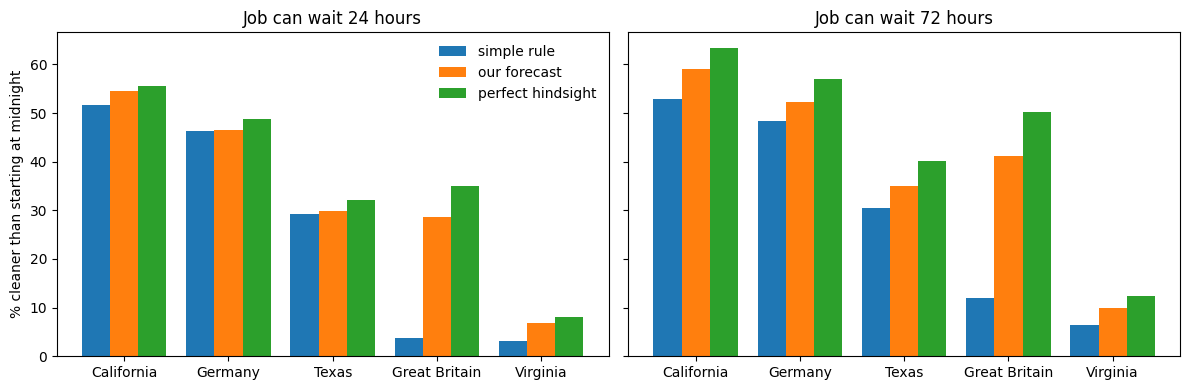

In [7]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

S = pd.read_csv("results/multigrid_summary.csv")
names = {
    "ciso": "California",
    "de": "Germany",
    "erco": "Texas",
    "gb": "Great Britain",
    "pjm": "Virginia",
}
order = ["ciso", "de", "erco", "gb", "pjm"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, slip in zip(axes, [24, 72]):
    d = S[S.slip_h == slip].set_index("grid").loc[order]
    x = np.arange(len(order))
    w = 0.27
    ax.bar(x - w, d.climatology_pct_saved, w, label="simple rule")
    ax.bar(x, d.model_pct_saved, w, label="our forecast")
    ax.bar(x + w, d.oracle_pct_saved, w, label="perfect hindsight")
    ax.set_xticks(x)
    ax.set_xticklabels([names[g] for g in order])
    ax.set_title(f"Job can wait {slip} hours")
axes[0].set_ylabel("% cleaner than starting at midnight")
axes[0].legend(frameon=False)
plt.tight_layout()
plt.show()

In [8]:
# the same numbers as a table, with the 95% intervals
cols = [
    "grid", "slip_h", "immediate", "persistence", "climatology",
    "model", "oracle", "model_pct_saved",
    "model_minus_climatology", "model_minus_climatology_lo",
    "model_minus_climatology_hi",
]
S[S.slip_h.isin([24, 72])][cols].round(1)

,grid,slip_h,immediate,persistence,climatology,model,oracle,model_pct_saved,model_minus_climatology,model_minus_climatology_lo,model_minus_climatology_hi
1,pjm,24,353.4,330.6,342.6,328.9,324.7,6.9,-13.8,-16.2,-11.7
3,pjm,72,353.4,330.6,331.0,318.2,309.7,10.0,-12.8,-16.3,-9.8
5,ciso,24,220.0,100.6,106.3,99.8,97.7,54.6,-6.4,-8.1,-4.2
7,ciso,72,220.0,100.6,103.8,90.0,80.5,59.1,-13.8,-17.8,-9.0
9,erco,24,338.2,238.6,239.1,237.3,229.8,29.8,-1.8,-3.5,-0.4
11,erco,72,338.2,238.6,235.0,220.1,202.5,34.9,-14.9,-21.0,-8.6
13,de,24,364.3,199.6,195.3,194.5,186.4,46.6,-0.8,-4.3,2.0
15,de,72,364.3,199.6,188.0,173.8,156.3,52.3,-14.1,-19.7,-7.3
17,gb,24,120.0,93.3,115.4,85.7,77.9,28.6,-29.7,-36.1,-23.9
19,gb,72,120.0,93.3,105.6,70.6,59.7,41.2,-35.0,-41.2,-30.1


**Reading it honestly.**
- Shifting helps everywhere, most in solar-rich grids.
- In California, Texas and Germany a simple "run at midday" rule is
  almost as good for same-day shifting. With 3 days of slack the model
  beats the rule in all five grids.
- Britain's official NESO forecast beats ours, so the live tab uses
  theirs.
- Virginia's grid is flat, so its savings are the smallest. Perfect
  hindsight would only add 1.3% at 24 hours, which is why we do not
  claim a large saving there.
- A negative "model minus climatology" means the model chose cleaner
  windows than the simple rule.

**Rerunning this notebook.** It is deterministic: the same code and the
same bundled data gave the same numbers in two runs. The last digit can
still move by up to about 2 g/kWh between machines, because the
gradient-boosting split depends on the scikit-learn version. The numbers
in `results/` and the README come from one such run.

## 5. One example
A single input and what comes out, using the saved 2026 forecasts. We
show one day where the advice helped and one where it backfired, because
the tool is not always right: against a 6 PM plug-in it was worse on
4.5% of days.

In [9]:
P = pd.read_csv("results/test_predictions_all.csv.gz")
P["day"] = pd.to_datetime(P["day"])


def recommend(grid, day, hours=4, wait=24, kwh=10.0, label=""):
    d = P[(P.grid == grid) & (P.day == pd.Timestamp(day))].sort_values("j")
    forecast, actual = d.pred.values, d.y.values

    def window_mean(a):
        return np.convolve(a, np.ones(hours) / hours, mode="valid")

    start = int(np.argmin(window_mean(forecast)[: wait + 1]))
    now_cost = window_mean(actual)[0]
    chosen = window_mean(actual)[start]
    saved = (now_cost - chosen) * kwh
    print(f"{label}{grid} {day}: {hours}-hour job, can wait {wait} hours")
    print(f"  advice: start {start} h after midnight")
    print(f"  midnight start {now_cost:.0f} g/kWh, our window {chosen:.0f} g/kWh")
    verdict = "less CO2 than midnight" if saved > 0 else "more CO2 than midnight"
    print(f"  CO2 avoided: {saved:+,.0f} g for {kwh:g} kWh ({verdict})")
    print()


recommend("pjm", "2026-02-04", hours=4, wait=24, kwh=10, label="HELPED: ")
recommend("pjm", "2026-01-09", hours=4, wait=24, kwh=10, label="BACKFIRED: ")

HELPED: pjm 2026-02-04: 4-hour job, can wait 24 hours
  advice: start 11 h after midnight
  midnight start 403 g/kWh, our window 378 g/kWh
  CO2 avoided: +244 g for 10 kWh (less CO2 than midnight)

BACKFIRED: pjm 2026-01-09: 4-hour job, can wait 24 hours
  advice: start 24 h after midnight
  midnight start 308 g/kWh, our window 345 g/kWh
  CO2 avoided: -369 g for 10 kWh (more CO2 than midnight)



## 6. The app
Two more files. The app has a Replay tab (days from 2026) and a Live
tab for Great Britain and Germany. You can pick an appliance or type
your own run time in hours.

### `app/live.py`: Live tab: Great Britain and Germany

In [10]:
%%writefile app/live.py
"""Live mode: cleanest time in the next 48 hours, from public forecasts.

Great Britain: NESO's official carbon forecast
  https://carbonintensity.org.uk/  (route /intensity/{from}/fw48h)
  We use their forecast, not ours, because it beat our model there
  in the 2026 tests (by about 4 to 6 g/kWh).
Germany: Energy-Charts (Fraunhofer ISE) renewable-share forecast
  https://api.energy-charts.info/ren_share_forecast
  This is the share of power from wind and sun, not grams of CO2,
  so for Germany we pick the hours with the most renewables and we
  never quote grams.
No keys needed. If something fails (offline, API change) we show a
friendly message instead of crashing.
"""
import json
import urllib.request

import numpy as np
import pandas as pd

APPLIANCES = {
    "Charge my electric car": (4, 10.0),
    "Run the dishwasher": (2, 1.2),
    "Do laundry (wash + dry)": (3, 3.0),
    "Heat water (boiler / heat pump)": (3, 3.0),
}
WAIT = {"Up to 12 hours": 12, "Up to 24 hours": 24, "Up to 36 hours": 36}
REGIONS = ["Great Britain", "Germany"]
TZ = {"Great Britain": "Europe/London", "Germany": "Europe/Berlin"}

# What counts as "usual" for the green / red message.
# Great Britain: app.py sets this to the median 2026 intensity.
# Germany: half of the power from renewables.
# If it is not set we use the median of the forecast on screen.
TYPICAL = {"Great Britain": None, "Germany": 50.0}


def pick_job(appliance, custom_hours=None, custom_kwh=None):
    """Hours and kWh for the job. Typed numbers beat the dropdown."""
    hours, kwh = APPLIANCES[appliance]
    if custom_hours:
        hours = int(round(custom_hours))
        hours = max(1, min(12, hours))
    if custom_kwh and custom_kwh > 0:
        kwh = float(custom_kwh)
    return hours, kwh


def fetch_forecast(now=None, timeout=10):
    """Great Britain: hourly forecast in g CO2 per kWh (UTC hour start)."""
    now = now or pd.Timestamp.now(tz="UTC")
    start = now.floor("30min").strftime("%Y-%m-%dT%H:%MZ")
    url = f"https://api.carbonintensity.org.uk/intensity/{start}/fw48h"
    raw = urllib.request.urlopen(url, timeout=timeout).read()
    rows = json.loads(raw)["data"]
    s = pd.Series(
        {pd.Timestamp(r["from"]): r["intensity"]["forecast"] for r in rows}
    )
    s = s.sort_index().dropna()
    return s.resample("h").mean().dropna().iloc[:48]


def fetch_germany(now=None, timeout=10):
    """Germany: hourly forecast renewable share in % (UTC hour start)."""
    now = now or pd.Timestamp.now(tz="UTC")
    url = "https://api.energy-charts.info/ren_share_forecast?country=de"
    d = json.loads(urllib.request.urlopen(url, timeout=timeout).read())
    times = pd.to_datetime(d["unix_seconds"], unit="s", utc=True)
    s = pd.Series(d["ren_share"], index=times, dtype=float).dropna()
    h = s.resample("h").mean().dropna()
    return h[h.index >= now.floor("h")].iloc[:48]


def colour(v, lo, hi):
    """Green for low values, red for high ones."""
    t = 0 if hi <= lo else min(max((v - lo) / (hi - lo), 0), 1)
    red = int(60 + 190 * t)
    green = int(190 - 110 * t)
    return f"rgb({red},{green},80)"


def label(ts, region="Great Britain"):
    t = ts.tz_convert(TZ[region])
    clock = (t.hour % 12) or 12
    ampm = "AM" if t.hour < 12 else "PM"
    return f"{t.strftime('%A, %b')} {t.day} at {clock} {ampm}"


def card_html(head, sub, frame, bg, border, text):
    sub = sub.replace("<b>", f"<b style='color:{text}'>")
    return (
        f"<div style='padding:18px;border-radius:12px;"
        f"background:{bg};border:1px solid {border}'>"
        f"<div style='font-size:28px;font-weight:700;color:{text}'>"
        f"{head}</div>"
        f"<div style='font-size:16px;margin-top:6px;color:#1f2937'>"
        f"{sub}</div>"
        f"<div style='font-size:13px;margin-top:6px;color:#374151'>"
        f"Your time frame: {frame}.</div></div>"
    )


def advise_live(
    appliance,
    wait,
    region="Great Britain",
    custom_hours=None,
    custom_kwh=None,
    series=None,
):
    try:
        if series is not None:
            h = series
        elif region == "Germany":
            h = fetch_germany()
        else:
            h = fetch_forecast()
    except Exception:  # offline, rate limit, API change
        return (
            "<div style='padding:14px;border-radius:10px;"
            "background:#fff4e5;border:1px solid #f0c987;color:#1f2937'>"
            f"Live data is not available right now (no internet or the "
            f"{region} feed is down). Use the Replay tab, which works "
            "offline.</div>"
        )

    hours, kwh = pick_job(appliance, custom_hours, custom_kwh)
    slip = WAIT[wait]
    share_mode = region == "Germany"
    # lower is cleaner, so flip the renewable share
    metric = (100 - h.values) if share_mode else h.values
    if len(metric) < hours + 2:
        return "<div>Not enough forecast yet. Try again in a minute.</div>"

    window = np.convolve(metric, np.ones(hours) / hours, mode="valid")
    window = window[: slip + 1]
    best = int(window.argmin())

    if share_mode:
        share_now = h.values[:hours].mean()
        share_best = h.values[best : best + hours].mean()
        gain = share_best - share_now  # points of renewable share
    else:
        gain = 100 * (window[0] - window[best]) / window[0]
    moved = gain >= 3

    last = min(len(h) - 1, slip)
    frame = f"{label(h.index[0], region)} to {label(h.index[last], region)}"
    bg, border, text = "#eaf6ee", "#bfe3c9", "#14532d"

    if not moved:
        best = 0
        usual = TYPICAL.get(region)
        if usual is None:
            usual = float(np.median(h.values))
        if share_mode:
            is_green = h.values[:hours].mean() >= usual
        else:
            is_green = window[0] <= usual
        if is_green:
            head = "Green: start whenever you like within your time frame"
            sub = (
                f"Power looks cleaner than usual all through {frame}, "
                "and no hour is much better than another."
            )
        else:
            bg, border, text = "#fdecea", "#f1b7b1", "#8a1c13"
            head = "Red: if you can, wait longer"
            sub = (
                f"Power looks dirtier than usual across {frame} and no "
                "hour is much cleaner. Pick a longer wait if you can, "
                "or start now if it cannot wait."
            )
    else:
        head = f"Start {label(h.index[best], region)}"
        if share_mode:
            sub = (
                f"The forecast renewable share is about "
                f"<b>{share_best:.0f}%</b> then, versus about "
                f"<b>{share_now:.0f}%</b> if you start now. "
                "More wind and sun means cleaner power."
            )
        else:
            saved = (window[0] - window[best]) * kwh
            sub = (
                f"The forecast says that is about <b>{gain:.0f}% "
                f"cleaner</b> than starting now (about {saved:,.0f} "
                f"grams of CO2 less for {kwh:g} kWh)."
            )

    lo, hi = np.percentile(metric, 5), np.percentile(metric, 95)
    unit = "% renewable" if share_mode else "g CO2 per kWh"
    cells = []
    for i, (ts, x) in enumerate(h.items()):
        chosen = best <= i < best + hours
        border_css = "3px solid #111" if chosen else "1px solid white"
        shade = (100 - x) if share_mode else x
        cells.append(
            f"<div title='{label(ts, region)}: {x:.0f} {unit}' "
            f"style='flex:1;min-width:8px;height:26px;"
            f"background:{colour(shade, lo, hi)};"
            f"border:{border_css};box-sizing:border-box'></div>"
        )

    source = "official NESO forecast"
    if share_mode:
        source = "Fraunhofer ISE Energy-Charts renewable-share forecast"
    return (
        card_html(head, sub, frame, bg, border, text)
        + f"<h4 style='margin:16px 0 4px'>The next {len(h)} hours "
        f"({region}, {source}), {hours}-hour job</h4>"
        + f"<div style='display:flex'>{''.join(cells)}</div>"
        + "<div style='font-size:13px;margin-top:8px'>"
        "<span style='color:#2a9d4a'>■</span> cleaner &nbsp;"
        "<span style='color:#d9534f'>■</span> dirtier &nbsp; "
        "<b>Black outline</b> = suggested time. Hover a block for "
        "the hour. Forecasts change, so check again before you start."
        "</div>"
    )

Overwriting app/live.py


### `app/app.py`: The app people use

In [11]:
%%writefile app/app.py
"""Clean-Hour: tells you the cleanest time to run a big appliance.

The Replay tab uses real days from 2026 that the model never saw.
The Live tab (Great Britain, Germany) uses today's public forecasts.
Run from the repo root:
    python app/app.py
"""
import importlib.util
import os

import gradio as gr
import numpy as np
import pandas as pd

HERE = os.path.dirname(os.path.abspath(__file__))
RES = os.path.join(HERE, "..", "results")
DF = pd.read_csv(
    os.path.join(RES, "test_predictions_all.csv.gz"), parse_dates=["day"]
)
SUM = pd.read_csv(os.path.join(RES, "multigrid_summary.csv"))

REGIONS = {
    "California, USA": "ciso",
    "Texas, USA": "erco",
    "Virginia / Mid-Atlantic, USA": "pjm",
    "Germany": "de",
    "Great Britain": "gb",
}
# label: (hours it runs, kWh per run)
APPLIANCES = {
    "Charge my electric car": (4, 10.0),
    "Run the dishwasher": (2, 1.2),
    "Do laundry (wash + dry)": (3, 3.0),
    "Heat water (boiler / heat pump)": (3, 3.0),
}
WAIT = {
    "Just tonight (up to 12 hours)": 12,
    "Until tomorrow (24 hours)": 24,
    "I'm flexible: up to 3 days": 72,
}

# only days that exist for all five regions
day_sets = [set(DF[DF.grid == g].day) for g in REGIONS.values()]
common = set.intersection(*day_sets)
DAYS = sorted(common)
DAY_LABELS = [d.strftime("%a %d %b %Y") for d in DAYS]


def pick_job(appliance, custom_hours=None, custom_kwh=None):
    """Hours and kWh for the job. Typed numbers beat the dropdown."""
    hours, kwh = APPLIANCES[appliance]
    if custom_hours:
        hours = int(round(custom_hours))
        hours = max(1, min(12, hours))
    if custom_kwh and custom_kwh > 0:
        kwh = float(custom_kwh)
    return hours, kwh


def clock(h):
    h = int(h) % 24
    ampm = "AM" if h < 12 else "PM"
    return f"{(h % 12) or 12} {ampm}"


def when(j, release):
    d = release + pd.Timedelta(hours=int(j))
    return f"{d.strftime('%A, %b')} {d.day} at {clock(d.hour)}"


def day_name(d):
    return f"{d.strftime('%a %b')} {d.day}"


def colour(v, lo, hi):
    """Green for low values, red for high ones."""
    t = 0 if hi <= lo else min(max((v - lo) / (hi - lo), 0), 1)
    red = int(60 + 190 * t)
    green = int(190 - 110 * t)
    return f"rgb({red},{green},80)"


def bar_html(prof, lo, hi, start, hours, nshow, release=None):
    """One row of 24 coloured blocks per day."""
    rows = []
    n_days = int(np.ceil(nshow / 24))
    for d in range(n_days):
        cells = []
        for h in range(24):
            j = d * 24 + h
            if j >= len(prof) or j >= nshow:
                cells.append("<div style='flex:1;height:22px'></div>")
                continue
            chosen = start <= j < start + hours
            border = "3px solid #111" if chosen else "1px solid white"
            cells.append(
                f"<div title='{clock(h)}: {prof[j]:.0f} g CO2 per kWh' "
                f"style='flex:1;height:22px;"
                f"background:{colour(prof[j], lo, hi)};"
                f"border:{border};box-sizing:border-box'></div>"
            )
        name = f"Day {d + 1}"
        if release is not None:
            when_day = release + pd.Timedelta(days=d)
            name += f": {day_name(when_day)}"
        rows.append(
            f"<div style='margin:3px 0'>"
            f"<div style='font-size:12px;color:#555'>{name}</div>"
            f"<div style='display:flex'>{''.join(cells)}</div></div>"
        )
    scale = (
        "<div style='display:flex;justify-content:space-between;"
        "font-size:12px;color:#555;margin-top:2px'>"
        "<span>12 AM</span><span>6 AM</span><span>12 PM</span>"
        "<span>6 PM</span><span>11 PM</span></div>"
    )
    legend = (
        "<div style='font-size:13px;margin-top:8px'>"
        "<span style='color:#2a9d4a'>■</span> cleaner power &nbsp;"
        "<span style='color:#d9534f'>■</span> dirtier power &nbsp; "
        "<b>Black outline</b> = the time we suggest</div>"
    )
    return "".join(rows) + scale + legend


def card_html(head, sub, frame, bg, border, text):
    # bold text needs its own colour or the dark theme makes it white
    sub = sub.replace("<b>", f"<b style='color:{text}'>")
    return (
        f"<div style='padding:18px;border-radius:12px;"
        f"background:{bg};border:1px solid {border}'>"
        f"<div style='font-size:28px;font-weight:700;color:{text}'>"
        f"{head}</div>"
        f"<div style='font-size:16px;margin-top:6px;color:#1f2937'>"
        f"{sub}</div>"
        f"<div style='font-size:13px;margin-top:6px;color:#374151'>"
        f"Your time frame: {frame}.</div></div>"
    )


def advise(region, appliance, wait, day_label, custom_hours=None,
           custom_kwh=None):
    g = REGIONS[region]
    hours, kwh = pick_job(appliance, custom_hours, custom_kwh)
    day = DAYS[DAY_LABELS.index(day_label)]
    d = DF[(DF.grid == g) & (DF.day == day)].sort_values("j")
    actual, forecast = d.y.values, d.pred.values

    def windows(a):
        # average of every window of this many hours
        return np.convolve(a, np.ones(hours) / hours, mode="valid")

    # we only have 76 hours of data, so long jobs can't wait the full 3 days
    slip = min(WAIT[wait], len(windows(forecast)) - 1)
    nshow = min(slip + hours, len(forecast))

    w_pred = windows(forecast)[: slip + 1]
    w_act = windows(actual)
    start = int(w_pred.argmin())
    now_pred, now_act = w_pred[0], w_act[0]
    gain_pred = 100 * (now_pred - w_pred[start]) / now_pred
    best = int(w_act[: slip + 1].argmin())
    gain_act = 100 * (now_act - w_act[start]) / now_act
    gain_best = 100 * (now_act - w_act[best]) / now_act
    grams = (now_act - w_act[start]) * kwh

    release = pd.Timestamp(day)
    typical = float(DF[DF.grid == g].clim.median())  # usual g/kWh here
    frame = f"{when(0, release)} to {when(slip, release)}"
    moved = gain_pred >= 3

    bg, border, text = "#eaf6ee", "#bfe3c9", "#14532d"
    if moved:
        end = start + hours
        head = f"Start {when(start, release)}"
        sub = (
            f"It will run until about {when(end, release)}. We expect "
            f"that to be about <b>{gain_pred:.0f}% cleaner</b> than "
            "starting at midnight."
        )
        if w_pred[start] > typical:
            sub += (
                " Heads-up: even this is dirtier than usual for your "
                "region, so if you can wait longer, choose the 3-day "
                "option."
            )
    else:
        start = 0
        if now_pred <= typical:
            head = "Green: start whenever you like within your time frame"
            sub = (
                "Power is cleaner than usual all through your time "
                "frame, and no hour is much better than another."
            )
        else:
            bg, border, text = "#fdecea", "#f1b7b1", "#8a1c13"
            head = "Red: if you can, wait longer"
            sub = (
                f"Power is dirtier than usual across your whole time "
                f"frame ({frame}) and no hour is much cleaner. Pick a "
                "longer wait (up to 3 days) to give the tool a cleaner "
                "window, or start now if it cannot wait."
            )
    frame += f" ({hours}-hour job)"
    card = card_html(head, sub, frame, bg, border, text)

    lo = np.percentile(forecast[:nshow], 5)
    hi = np.percentile(forecast[:nshow], 95)
    n_days = int(np.ceil(nshow / 24))
    strip = (
        f"<h4 style='margin:16px 0 4px'>The forecast for the next "
        f"{n_days} day(s)</h4>"
        + bar_html(forecast, lo, hi, start, hours, nshow, release)
    )

    if moved and gain_act < 0:
        outcome = (
            "This time the advice backfired: the run came out "
            f"<b>{-gain_act:.0f}% dirtier</b> than starting at midnight "
            f"(perfect hindsight would have been {gain_best:.0f}% "
            f"cleaner). For a {kwh:g} kWh job that is about "
            f"<b>{-grams:,.0f} grams of CO2</b> extra."
        )
    elif moved:
        outcome = (
            f"Following the advice cut the CO2 of this run by "
            f"<b>{gain_act:.0f}%</b> compared with starting at midnight "
            f"(the best possible choice, with perfect hindsight, was "
            f"{gain_best:.0f}%). For a {kwh:g} kWh job that is about "
            f"<b>{grams:,.0f} grams of CO2</b> avoided."
        )
    else:
        outcome = (
            "The advice was to start right away, so there is no saving "
            "to report. With perfect hindsight the best choice in this "
            f"window would have been {gain_best:.0f}% cleaner than "
            "midnight."
        )
    looked_back = (
        "<h4 style='margin:16px 0 4px'>What actually happened</h4>"
        f"<div style='font-size:15px'>{outcome}</div>"
        + bar_html(actual, lo, hi, start, hours, nshow, release)
    )
    return card + strip, looked_back


def scorecard(region, wait):
    g = REGIONS[region]
    slip = WAIT[wait]
    r = SUM[(SUM.grid == g) & (SUM.slip_h == slip)].iloc[0]
    if abs(r.model_minus_climatology) < 5:
        note = (
            "*In this region the simple rule is almost as good for "
            "same-day shifting. Forecasting matters more the longer "
            "you can wait.*"
        )
    else:
        note = "*Here the forecast clearly beats the simple rule.*"
    return (
        f"**How good is this in {region}?** We tested on every day of "
        f"2026 (days the model never saw), for a 4-hour job that can "
        f"wait {slip} hours.\n\n"
        f"- Starting at midnight: **{r.immediate:.0f}** g CO2 per kWh\n"
        f"- Our advice: **{r.model:.0f}** g "
        f"(about **{r.model_pct_saved:.0f}% cleaner**)\n"
        f"- A simple rule (\"run at the cleanest hour of an average "
        f"week\"): {r.climatology:.0f} g "
        f"({r.climatology_pct_saved:.0f}% cleaner)\n"
        f"- Perfect hindsight: {r.oracle:.0f} g "
        f"({r.oracle_pct_saved:.0f}% cleaner)\n\n" + note
    )


INTRO = (
    "# 🌍 Clean-Hour\n"
    "### When is electricity cleanest? Run big appliances then.\n"
    "Built for Northern Virginia (home of Loudoun's data centers), "
    "and also tested in California, Texas, Germany and Britain. "
    "Power plants burn more coal and gas at some hours than others. "
    "Pick your region and appliance and we'll tell you the cleanest "
    "time to start it. (This tab replays real days from 2026.)"
)
LIMITS = (
    "- We use the **average** carbon intensity of your region's whole "
    "power grid, not your own electricity company and not the effect "
    "of one extra appliance (marginal emissions).\n"
    "- This tab is a replay of past days. The Live tab uses today's "
    "forecasts for Great Britain and Germany.\n"
    "- Savings are measured against starting at midnight. If you "
    "already run things at midday in a sunny region, you win already.\n"
    "- The accuracy numbers are for a 4-hour job. Other run times use "
    "the same method but were not scored separately.\n"
    "- Prototype for education, not an energy-bill or environmental "
    "guarantee."
)

with gr.Blocks(title="Clean-Hour") as demo:
    gr.Markdown(INTRO)
    with gr.Column(scale=1):
        region = gr.Dropdown(
            list(REGIONS),
            value="Virginia / Mid-Atlantic, USA",
            label="1. Where do you live?",
        )
        appliance = gr.Dropdown(
            list(APPLIANCES),
            value="Charge my electric car",
            label="2. What do you want to run?",
        )
        with gr.Row():
            hours_box = gr.Number(
                value=None,
                precision=0,
                minimum=1,
                maximum=12,
                label="Or type your own run time (hours, 1 to 12)",
            )
            kwh_box = gr.Number(
                value=None,
                minimum=0,
                label="Energy it uses (kWh, optional)",
            )
        wait = gr.Radio(
            list(WAIT),
            value="Until tomorrow (24 hours)",
            label="3. How long can it wait?",
        )
        with gr.Row():
            day = gr.Dropdown(
                DAY_LABELS,
                value=DAY_LABELS[120],
                label="4. Pick a day to try (real days from 2026)",
            )
            surprise = gr.Button("🎲 Surprise me", scale=0)
    go = gr.Button("Find the cleanest time", variant="primary", size="lg")
    answer = gr.HTML()
    with gr.Accordion("What actually happened? (hindsight check)", open=False):
        hindsight = gr.HTML()
    with gr.Accordion("How accurate is this? (honest numbers)", open=False):
        score = gr.Markdown()
    with gr.Accordion("What this does NOT tell you", open=False):
        gr.Markdown(LIMITS)

    def update(region, appliance, wait, day, hours, kwh):
        a, h = advise(region, appliance, wait, day, hours, kwh)
        return a, h, scorecard(region, wait)

    inputs = [region, appliance, wait, day, hours_box, kwh_box]
    outputs = [answer, hindsight, score]
    go.click(update, inputs, outputs)
    for box in (region, appliance, wait, day, hours_box, kwh_box):
        box.change(update, inputs, outputs)

    def random_day():
        return DAY_LABELS[int(np.random.randint(0, len(DAY_LABELS)))]

    surprise.click(random_day, None, day)
    demo.load(update, inputs, outputs)

# ---- Live tab: Great Britain and Germany -------------------------------
# If the live code fails to load we still keep the replay tab working.
try:
    spec = importlib.util.spec_from_file_location(
        "clean_hour_live", os.path.join(HERE, "live.py")
    )
    live = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(live)
except Exception:
    live = None

if live is not None:
    live.TYPICAL["Great Britain"] = float(DF[DF.grid == "gb"].y.median())
    with gr.Blocks(title="Clean-Hour live") as live_demo:
        gr.Markdown(
            "### Live: the next 48 hours in Great Britain or Germany\n"
            "Great Britain uses the official National Energy System "
            "Operator carbon forecast (it beat our own model there in "
            "the 2026 tests). Germany uses the Fraunhofer ISE "
            "renewable-share forecast (more wind and sun = cleaner). "
            "Needs internet."
        )
        with gr.Column():
            l_app = gr.Dropdown(
                list(live.APPLIANCES),
                value="Charge my electric car",
                label="What do you want to run?",
            )
            with gr.Row():
                l_hours = gr.Number(
                    value=None,
                    precision=0,
                    minimum=1,
                    maximum=12,
                    label="Or type your own run time (hours, 1 to 12)",
                )
                l_kwh = gr.Number(
                    value=None,
                    minimum=0,
                    label="Energy it uses (kWh, optional)",
                )
            l_wait = gr.Radio(
                list(live.WAIT),
                value="Up to 24 hours",
                label="How long can it wait?",
            )
            l_region = gr.Radio(
                live.REGIONS, value="Great Britain", label="Where?"
            )
            l_go = gr.Button("Find the cleanest time now", variant="primary")
            l_out = gr.HTML()
        l_go.click(
            live.advise_live,
            [l_app, l_wait, l_region, l_hours, l_kwh],
            l_out,
        )
    app = gr.TabbedInterface(
        [demo, live_demo],
        [
            "Replay: Virginia and 4 more regions (tested on 2026)",
            "Live: Great Britain and Germany",
        ],
        title=None,
    )
else:
    app = demo

if __name__ == "__main__":
    app.launch(theme=gr.themes.Soft(primary_hue="green"))

Overwriting app/app.py


In [12]:
import importlib.util
import warnings

warnings.filterwarnings("ignore")   # gradio pulls a tqdm/ipywidgets warning we do not need
spec = importlib.util.spec_from_file_location("clean_hour_app", "app/app.py")
mod = importlib.util.module_from_spec(spec)
spec.loader.exec_module(mod)

if "google.colab" in sys.modules:
    mod.app.launch(share=True, debug=False)
else:
    print("Loaded. To run it on your computer:")
    print("    python app/app.py   then open http://127.0.0.1:7860")

Loaded. To run it on your computer:
    python app/app.py   then open http://127.0.0.1:7860


## 7. Sources and credits
- EIA grid data: https://www.eia.gov/electricity/gridmonitor/
- Energy-Charts (Fraunhofer ISE): https://api.energy-charts.info/
- NESO Carbon Intensity API: https://carbonintensity.org.uk/
- Open-Meteo: https://open-meteo.com/en/docs/historical-forecast-api
- Emission factors: IPCC AR5 WG3 Annex III
  (https://www.ipcc.ch/report/ar5/wg3/). Oil and "other fuels" values
  are our own assumptions.
- Tools: pandas, scikit-learn, matplotlib, Gradio.
- Related work is listed in `README.md` and `CREDITS.md`.
- AI tool: we used Claude Code (Anthropic) to help write and test this
  code. The full list of tools is in `CREDITS.md`, and the team
  reviewed the results and can explain every part.